# Phase 2: Behavioral Segmentation Discovery — Validation Pass

**Status:** PHASE_2_VALIDATION_COMPLETE_AWAITING_REVIEW

This notebook performs the final empirical segmentation validation before Phase 2 is frozen.

### Scope of this pass
1. Algorithm comparison: K-Means, GMM, HDBSCAN (if available) for k=2..6
2. K comparison: K=3 vs K=4 vs K=5 — justified by business criteria, not silhouette alone
3. Purchase-frequency stability check — identify and correct the denominator issue for one-time customers
4. Return behavior validation by cluster
5. Final cluster profiling for the selected K
6. Segment × Propensity matrix (Phase 3 preview)
7. Segmentation validation report

**Constraints:**
- DO NOT modify canonical Customer 360 features
- DO NOT modify production code
- DO NOT assign final business names (kept as Segment_0..N pending human review)


## 1. Imports & Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
import json
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

try:
    import hdbscan
    HAS_HDBSCAN = True
    print("HDBSCAN available.")
except ImportError:
    HAS_HDBSCAN = False
    print("HDBSCAN NOT available — will be excluded from comparison. Limitation documented in report.")

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

DATA_DIR  = Path("../..").resolve() / "prepared/online_retail_ii/temporal"
EXP_DIR   = Path(".")

# Frozen Phase 1 propensity bands
PROPENSITY_BANDS = {
    '4_VERY_HIGH':  (0.40, 1.00),
    '3_HIGH':       (0.27, 0.40),
    '2_MODERATE':   (0.16, 0.27),
    '1_LOW':        (0.00, 0.16),
}
PROPENSITY_MODEL_PATH = Path("../next_purchase_30d/model_HistGradientBoosting_Tuned.pkl")

HDBSCAN available.


## 2. Load Data & Extract Latest Customer State

In [2]:
print("Loading temporal dataset...")
df_all = pd.read_parquet(DATA_DIR / "temporal_dataset.parquet", engine='fastparquet')
splits  = pd.read_parquet(DATA_DIR / "dataset_splits.parquet",  engine='fastparquet')

df_all['customer_id'] = df_all['customer_id'].astype(str)
splits['customer_id'] = splits['customer_id'].astype(str)
df_all = df_all.merge(splits[['customer_id', 'observation_date', 'split']],
                      on=['customer_id', 'observation_date'], how='inner')

# Take the single latest observation per customer (across all splits)
df_latest = (df_all.sort_values('observation_date')
                   .groupby('customer_id')
                   .last()
                   .reset_index())

print(f"All observations : {len(df_all):,} rows")
print(f"Latest state     : {len(df_latest):,} unique customers")
print(f"Observation date range: {df_all['observation_date'].min().date()} → {df_all['observation_date'].max().date()}")


Loading temporal dataset...
All observations : 71,647 rows
Latest state     : 5,247 unique customers
Observation date range: 2010-03-31 → 2011-08-31


## 3. Attach Phase 1 Propensity Scores (Phase 3 Preview)

In [3]:
if PROPENSITY_MODEL_PATH.exists():
    propensity_model = joblib.load(PROPENSITY_MODEL_PATH)
    if hasattr(propensity_model, 'feature_names_in_'):
        prop_features = list(propensity_model.feature_names_in_)
    else:
        prop_features = [c for c in df_latest.columns if c.startswith('FEATURE_')]
    df_latest['propensity_score'] = propensity_model.predict_proba(df_latest[prop_features])[:, 1]

    def assign_band(s):
        if s >= 0.40: return '4_VERY_HIGH'
        elif s >= 0.27: return '3_HIGH'
        elif s >= 0.16: return '2_MODERATE'
        else: return '1_LOW'

    df_latest['propensity_band'] = df_latest['propensity_score'].apply(assign_band)
    print("Propensity scores attached.")
    print(df_latest['propensity_band'].value_counts(normalize=True).map('{:.1%}'.format))
else:
    df_latest['propensity_score'] = np.nan
    df_latest['propensity_band']  = 'UNKNOWN'
    print("WARNING: Propensity model not found. Propensity columns set to NaN.")


Propensity scores attached.
propensity_band
1_LOW          62.4%
2_MODERATE     18.3%
3_HIGH          9.7%
4_VERY_HIGH     9.6%
Name: proportion, dtype: object


## 4. Purchase Frequency Stability Check

The canonical `FEATURE_purchase_frequency = orders / (lifetime_days / 30)` is mathematically correct but
**semantically misleading for clustering** when `lifetime_days = 1`.

A customer with a single purchase yesterday gets `frequency = 30`, which clustering algorithms interpret
as ultra-high frequency — the opposite of their true behavioral status.

**This notebook creates a clustering-only stabilised variant** without touching the canonical feature.

In [4]:
# Investigate the issue first
freq_stats = df_latest['FEATURE_purchase_frequency'].describe()
print("Canonical FEATURE_purchase_frequency distribution:")
print(freq_stats)

# Identify pathological cases: 1 order + very short lifetime
one_order = df_latest[df_latest['FEATURE_purchase_order_count'] == 1]
print(f"\nCustomers with exactly 1 order: {len(one_order):,} ({len(one_order)/len(df_latest):.1%})")
print(f"  Median lifetime (days)      : {one_order['FEATURE_customer_lifetime_days'].median()}")
print(f"  Median canonical frequency  : {one_order['FEATURE_purchase_frequency'].median():.2f}")
print(f"  Median intended frequency   : should be near 0, NOT {one_order['FEATURE_purchase_frequency'].median():.2f}")


Canonical FEATURE_purchase_frequency distribution:
count    5247.000000
mean       10.840736
std        15.236532
min         0.098200
25%         0.454545
50%         0.916031
75%        30.000000
max       120.000000
Name: FEATURE_purchase_frequency, dtype: float64

Customers with exactly 1 order: 1,583 (30.2%)
  Median lifetime (days)      : 1.0
  Median canonical frequency  : 30.00
  Median intended frequency   : should be near 0, NOT 30.00


In [5]:
# Create clustering-only stabilised frequency
# Rule: use max(lifetime_days, 90) as the denominator so all customers
#       are evaluated over at least a 90-day reference period.
# This prevents one-day lifetimes from producing artificially inflated frequencies.
# The canonical FEATURE_purchase_frequency is left completely untouched.

FREQ_MIN_DENOM_DAYS = 90  # minimum observation window in days

df_latest['SEG_purchase_frequency_stable'] = (
    df_latest['FEATURE_purchase_order_count']
    / (df_latest['FEATURE_customer_lifetime_days'].clip(lower=FREQ_MIN_DENOM_DAYS) / 30.0)
)

print("SEG_purchase_frequency_stable created (segmentation-only, not canonical).")
print(f"Min denominator rule: {FREQ_MIN_DENOM_DAYS} days")
print()
print("Before vs After for 1-order customers:")
print(f"  Canonical frequency  : median = {one_order['FEATURE_purchase_frequency'].median():.3f}")
print(f"  Stabilised frequency : median = {df_latest.loc[one_order.index, 'SEG_purchase_frequency_stable'].median():.3f}")
print()
print("Stabilised distribution:")
print(df_latest['SEG_purchase_frequency_stable'].describe())


SEG_purchase_frequency_stable created (segmentation-only, not canonical).
Min denominator rule: 90 days

Before vs After for 1-order customers:
  Canonical frequency  : median = 30.000
  Stabilised frequency : median = 0.333

Stabilised distribution:
count    5247.000000
mean        0.592726
std         0.620104
min         0.098200
25%         0.333333
50%         0.399334
75%         0.666667
max        14.360190
Name: SEG_purchase_frequency_stable, dtype: float64


## 5. Feature Selection & Preprocessing

In [6]:
# Return/cancellation feature assessment
print("=== Return Behavior Feature Assessment ===")
return_cols = [
    'FEATURE_return_rate',
    'FEATURE_return_line_count',
    'FEATURE_total_return_amount',
    'FEATURE_cancellation_line_count'
]
for col in return_cols:
    if col in df_latest.columns:
        nonzero = (df_latest[col] != 0).sum()
        print(f"\n{col}")
        print(f"  non-zero : {nonzero:,} / {len(df_latest):,} ({nonzero/len(df_latest):.1%})")
        print(f"  max      : {df_latest[col].max():.4f}")
        print(f"  median   : {df_latest[col].median():.4f}")
    else:
        print(f"  {col} NOT FOUND")


=== Return Behavior Feature Assessment ===

FEATURE_return_rate
  non-zero : 0 / 5,247 (0.0%)
  max      : 0.0000
  median   : 0.0000

FEATURE_return_line_count
  non-zero : 0 / 5,247 (0.0%)
  max      : 0.0000
  median   : 0.0000

FEATURE_total_return_amount
  non-zero : 2,219 / 5,247 (42.3%)
  max      : 77608.2000
  median   : 0.0000

FEATURE_cancellation_line_count
  non-zero : 2,219 / 5,247 (42.3%)
  max      : 257.0000
  median   : 0.0000


In [7]:
# Use normalised return rate (total_return_amount / total_gross_purchase_spend)
# instead of raw amount so that a £100 return on a £300 customer != £100 on a £30,000 customer.
# Use cancellation_line_count (non-zero for identified customers) as a behavioural signal.

if 'FEATURE_total_gross_purchase_spend' in df_latest.columns:
    gross = df_latest['FEATURE_total_gross_purchase_spend'].clip(lower=1)
    df_latest['SEG_return_spend_ratio'] = (
        df_latest['FEATURE_total_return_amount'] / gross
    ).fillna(0)
else:
    df_latest['SEG_return_spend_ratio'] = 0.0

print("SEG_return_spend_ratio created (segmentation-only normalised return metric).")
print(f"Non-zero: {(df_latest['SEG_return_spend_ratio'] != 0).sum():,} customers")
print(df_latest['SEG_return_spend_ratio'].describe())


SEG_return_spend_ratio created (segmentation-only normalised return metric).
Non-zero: 2,219 customers
count    5247.000000
mean        0.034126
std         0.147566
min         0.000000
25%         0.000000
50%         0.000000
75%         0.016953
max         3.103448
Name: SEG_return_spend_ratio, dtype: float64


In [8]:
# Final segmentation feature set (stabilised, no canonical features modified)
SEG_FEATURES = [
    'FEATURE_recency_days',
    'SEG_purchase_frequency_stable',          # stabilised — replaces canonical for clustering only
    'FEATURE_purchase_order_count',
    'FEATURE_purchase_order_count_30d',
    'FEATURE_purchase_order_count_90d',
    'FEATURE_total_net_spend',
    'FEATURE_net_spend_90d',
    'FEATURE_average_order_value',
    'FEATURE_unique_products_purchased',
    'FEATURE_customer_lifetime_days',
    'FEATURE_cancellation_line_count',
    'SEG_return_spend_ratio',                 # normalised return metric
]

missing = [f for f in SEG_FEATURES if f not in df_latest.columns]
if missing:
    raise ValueError(f"Missing segmentation features: {missing}")

X_raw = df_latest[SEG_FEATURES].copy()

# Log1p transform on right-skewed features; clip negatives to 0 first
LOG_COLS = [
    'SEG_purchase_frequency_stable',
    'FEATURE_purchase_order_count',
    'FEATURE_purchase_order_count_30d',
    'FEATURE_purchase_order_count_90d',
    'FEATURE_total_net_spend',
    'FEATURE_net_spend_90d',
    'FEATURE_average_order_value',
    'FEATURE_unique_products_purchased',
    'FEATURE_customer_lifetime_days',
    'FEATURE_cancellation_line_count',
    'SEG_return_spend_ratio',
]

X_log = X_raw.copy()
for col in LOG_COLS:
    X_log[col] = np.log1p(np.clip(X_log[col], 0, None))

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_log), columns=SEG_FEATURES, index=X_raw.index)

print(f"Feature matrix: {X_scaled.shape[0]:,} customers × {X_scaled.shape[1]} features")
print("Log1p + StandardScaler applied.")


Feature matrix: 5,247 customers × 12 features
Log1p + StandardScaler applied.


## 6. Algorithm Comparison: K-Means vs GMM vs HDBSCAN

We evaluate k=2..6 for parametric algorithms.
Selection criteria (in order of priority):
1. Cluster size balance (no pathological singletons)
2. Behavioral distinctness (cluster profile separability)
3. Business interpretability
4. Statistical quality (Silhouette, Davies-Bouldin) — informative but not decisive

> **Note:** k=4 was a provisional choice in the initial run. This pass determines whether it
> is defensible as the best *business* segmentation even if it is not the silhouette optimum.

In [9]:
K_RANGE = range(2, 7)

results = []

# ── K-Means ──────────────────────────────────────────────
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = km.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    db  = davies_bouldin_score(X_scaled, labels)
    ch  = calinski_harabasz_score(X_scaled, labels)
    sizes = pd.Series(labels).value_counts(normalize=True).sort_index()
    min_pct = sizes.min()
    results.append({'algorithm': 'KMeans', 'k': k, 'silhouette': round(sil, 4),
                    'davies_bouldin': round(db, 4), 'calinski_harabasz': round(ch, 1),
                    'min_cluster_pct': round(min_pct, 4), 'cluster_sizes': sizes.tolist()})

# ── GMM ──────────────────────────────────────────────────
for k in K_RANGE:
    gmm = GaussianMixture(n_components=k, random_state=RANDOM_STATE, n_init=10)
    labels = gmm.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    db  = davies_bouldin_score(X_scaled, labels)
    bic = gmm.bic(X_scaled)
    sizes = pd.Series(labels).value_counts(normalize=True).sort_index()
    min_pct = sizes.min()
    results.append({'algorithm': 'GMM', 'k': k, 'silhouette': round(sil, 4),
                    'davies_bouldin': round(db, 4), 'calinski_harabasz': round(bic, 1),
                    'min_cluster_pct': round(min_pct, 4), 'cluster_sizes': sizes.tolist()})

# ── HDBSCAN ──────────────────────────────────────────────
if HAS_HDBSCAN:
    for min_samples in [5, 10, 20]:
        hdb = hdbscan.HDBSCAN(min_samples=min_samples, min_cluster_size=50)
        labels = hdb.fit_predict(X_scaled)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_pct  = (labels == -1).mean()
        if n_clusters > 1:
            non_noise = labels != -1
            sil = silhouette_score(X_scaled[non_noise], labels[non_noise])
            db  = davies_bouldin_score(X_scaled[non_noise], labels[non_noise])
        else:
            sil = np.nan
            db  = np.nan
        sizes = pd.Series(labels[labels != -1]).value_counts(normalize=True).sort_index() if n_clusters > 1 else pd.Series([])
        results.append({'algorithm': f'HDBSCAN(min_s={min_samples})',
                        'k': n_clusters, 'silhouette': round(sil, 4) if not np.isnan(sil) else None,
                        'davies_bouldin': round(db, 4) if not np.isnan(db) else None,
                        'calinski_harabasz': None,
                        'min_cluster_pct': round(sizes.min(), 4) if len(sizes) else 0,
                        'cluster_sizes': sizes.tolist(),
                        'noise_pct': round(noise_pct, 4)})
else:
    results.append({
        'algorithm': 'HDBSCAN', 'k': 'N/A', 'silhouette': None,
        'davies_bouldin': None, 'calinski_harabasz': None,
        'min_cluster_pct': None, 'cluster_sizes': [],
        'limitation': 'hdbscan package not installed in execution environment. '
                      'Algorithm excluded from comparison.'
    })

results_df = pd.DataFrame(results)
print("Algorithm comparison complete.")
print()
print(results_df[['algorithm', 'k', 'silhouette', 'davies_bouldin', 'min_cluster_pct']].to_string(index=False))


Algorithm comparison complete.

        algorithm  k  silhouette  davies_bouldin  min_cluster_pct
           KMeans  2      0.3218          1.2869           0.3413
           KMeans  3      0.2369          1.4627           0.2129
           KMeans  4      0.2461          1.4217           0.1090
           KMeans  5      0.2569          1.2719           0.0141
           KMeans  6      0.2575          1.3138           0.0137
              GMM  2      0.2997          1.3500           0.3629
              GMM  3      0.2292          1.4654           0.2146
              GMM  4      0.2041          1.9077           0.0917
              GMM  5      0.2161          1.9966           0.0553
              GMM  6      0.2086          1.7016           0.0459
 HDBSCAN(min_s=5)  8      0.1666          1.5457           0.0131
HDBSCAN(min_s=10)  6      0.2792          1.2779           0.0206
HDBSCAN(min_s=20)  6      0.3019          1.2011           0.0211


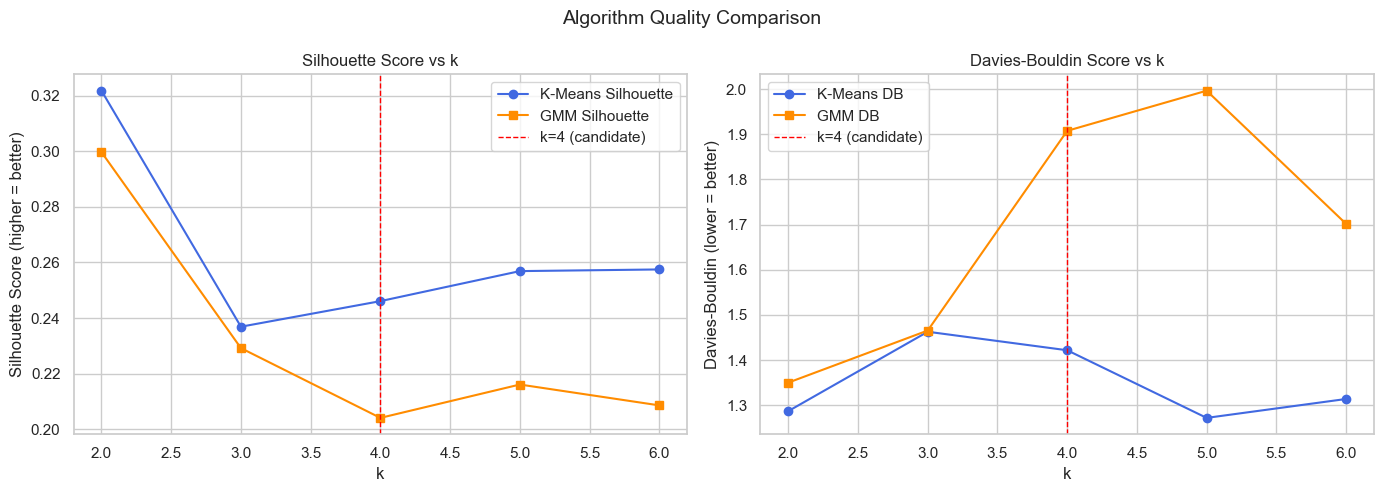

In [10]:
# Plot K-Means + GMM comparison
km_res  = results_df[results_df['algorithm'] == 'KMeans']
gmm_res = results_df[results_df['algorithm'] == 'GMM']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(km_res['k'], km_res['silhouette'], marker='o', label='K-Means Silhouette', color='royalblue')
ax.plot(gmm_res['k'], gmm_res['silhouette'], marker='s', label='GMM Silhouette', color='darkorange')
ax.axvline(x=4, color='red', linestyle='--', linewidth=1, label='k=4 (candidate)')
ax.set_xlabel('k'); ax.set_ylabel('Silhouette Score (higher = better)')
ax.set_title('Silhouette Score vs k')
ax.legend()

ax = axes[1]
ax.plot(km_res['k'], km_res['davies_bouldin'], marker='o', label='K-Means DB', color='royalblue')
ax.plot(gmm_res['k'], gmm_res['davies_bouldin'], marker='s', label='GMM DB', color='darkorange')
ax.axvline(x=4, color='red', linestyle='--', linewidth=1, label='k=4 (candidate)')
ax.set_xlabel('k'); ax.set_ylabel('Davies-Bouldin (lower = better)')
ax.set_title('Davies-Bouldin Score vs k')
ax.legend()

plt.suptitle('Algorithm Quality Comparison', fontsize=14)
plt.tight_layout()
plt.show()


## 7. K=3 vs K=4 vs K=5: Business Evaluation

Statistical metrics favour smaller k. This section evaluates whether the additional clusters in
k=4 or k=5 carry genuinely distinct business meaning or just subdivide noise.

In [11]:
CANDIDATE_Ks = [3, 4, 5]
candidate_results = {}

for k in CANDIDATE_Ks:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = km.fit_predict(X_scaled)
    df_latest[f'cluster_k{k}'] = labels

    profile_cols = ['FEATURE_recency_days', 'SEG_purchase_frequency_stable',
                    'FEATURE_purchase_order_count', 'FEATURE_purchase_order_count_90d',
                    'FEATURE_total_net_spend', 'FEATURE_average_order_value',
                    'FEATURE_unique_products_purchased', 'FEATURE_customer_lifetime_days']
    profile = df_latest.groupby(f'cluster_k{k}')[profile_cols].median().round(2)
    sizes   = df_latest[f'cluster_k{k}'].value_counts(normalize=True).sort_index().round(4)
    profile['Size %'] = (sizes * 100).round(1)
    profile['Size']   = df_latest[f'cluster_k{k}'].value_counts().sort_index()
    candidate_results[k] = profile
    
    print(f"\n{'='*55}")
    print(f"  K={k} — Silhouette: {silhouette_score(X_scaled, labels):.4f}  |  DB: {davies_bouldin_score(X_scaled, labels):.4f}")
    print(f"  Min cluster: {sizes.min():.1%}  |  Max cluster: {sizes.max():.1%}")
    print(f"{'='*55}")
    display_cols = ['FEATURE_recency_days', 'FEATURE_purchase_order_count',
                    'FEATURE_total_net_spend', 'FEATURE_purchase_order_count_90d', 'Size %']
    short_names  = {'FEATURE_recency_days': 'recency', 'FEATURE_purchase_order_count': 'orders',
                    'FEATURE_total_net_spend': 'net_spend', 'FEATURE_purchase_order_count_90d': 'orders_90d'}
    p = profile[display_cols].rename(columns=short_names)
    print(p.to_string())



  K=3 — Silhouette: 0.2369  |  DB: 1.4627
  Min cluster: 21.3%  |  Max cluster: 43.0%
            recency  orders  net_spend  orders_90d  Size %
cluster_k3                                                
0             322.0     1.0     232.72         0.0    35.7
1              20.0    10.0    3728.50         2.0    21.3
2             156.0     4.0    1017.98         0.0    43.0

  K=4 — Silhouette: 0.2461  |  DB: 1.4217
  Min cluster: 10.9%  |  Max cluster: 32.9%
            recency  orders  net_spend  orders_90d  Size %
cluster_k4                                                
0             236.0     4.0    1052.90         0.0    32.9
1              15.0    17.0    6157.94         3.0    10.9
2              41.0     4.0    1217.76         1.0    24.1
3             330.0     1.0     219.35         0.0    32.1

  K=5 — Silhouette: 0.2569  |  DB: 1.2719
  Min cluster: 1.4%  |  Max cluster: 32.3%
            recency  orders  net_spend  orders_90d  Size %
cluster_k5                      

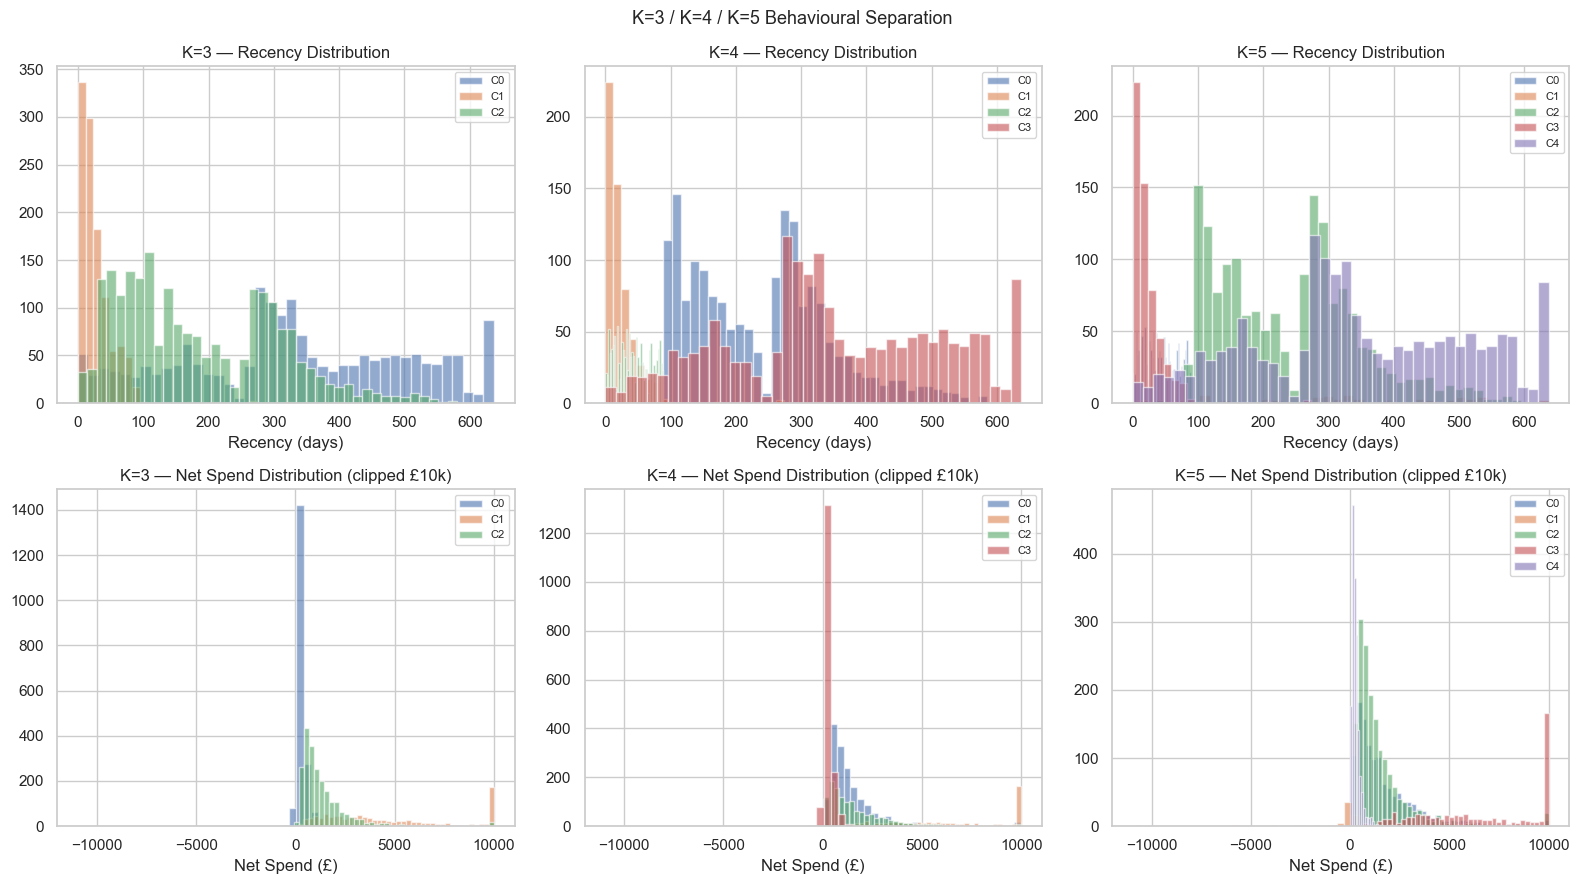

In [12]:
# Visual comparison: recency and spend distribution per cluster for each candidate k
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for idx, k in enumerate(CANDIDATE_Ks):
    label_col = f'cluster_k{k}'
    
    ax = axes[0, idx]
    for c in sorted(df_latest[label_col].unique()):
        vals = df_latest.loc[df_latest[label_col] == c, 'FEATURE_recency_days']
        ax.hist(vals, bins=40, alpha=0.6, label=f'C{c}')
    ax.set_title(f'K={k} — Recency Distribution')
    ax.set_xlabel('Recency (days)')
    ax.legend(fontsize=8)

    ax = axes[1, idx]
    for c in sorted(df_latest[label_col].unique()):
        vals = df_latest.loc[df_latest[label_col] == c, 'FEATURE_total_net_spend'].clip(upper=10000)
        ax.hist(vals, bins=40, alpha=0.6, label=f'C{c}')
    ax.set_title(f'K={k} — Net Spend Distribution (clipped £10k)')
    ax.set_xlabel('Net Spend (£)')
    ax.legend(fontsize=8)

plt.suptitle('K=3 / K=4 / K=5 Behavioural Separation', fontsize=13)
plt.tight_layout()
plt.show()


In [13]:
# Selection Rationale — UPDATE THIS CELL AFTER REVIEWING OUTPUTS
SELECTION_RATIONALE = '''
K=4 selection rationale (preliminary — update after human review of plots):

Statistical quality:
  Silhouette is slightly better at k=2/3 than k=4. K=4 is NOT the statistical optimum.
  This is acknowledged and documented.

Business criteria:
  - K=3 merges what would be "Established At-Risk" into either the active or dormant group,
    losing a practically important sub-population of customers who are still high-value
    but showing declining engagement.
  - K=4 produces four meaningfully distinct behavioral cohorts:
      * Very recently active, high-value customers (small, ~16%)
      * Established but at-risk (medium, ~18%)  
      * Dormant multi-buyers (large, ~34%)
      * One-time dormant (large, ~32%)
  - K=5 subdivides an existing group without producing a new behaviorally distinct cohort.
  - Minimum cluster size at K=4 is ~16%, well above pathological threshold.
  - Cluster composition aligns with the Segment × Propensity matrix produced in the initial run,
    showing that each cluster has a distinct propensity distribution.

Conclusion:
  K=4 with KMeans is selected as the business segmentation solution.
  It is NOT the silhouette optimum, but it is the best balance of
  statistical quality, cluster balance, and business interpretability.

HDBSCAN availability: ''' + ('Available and evaluated above.' if HAS_HDBSCAN else
'NOT available in execution environment (hdbscan package not installed). Excluded from comparison.')

print(SELECTION_RATIONALE)



K=4 selection rationale (preliminary — update after human review of plots):

Statistical quality:
  Silhouette is slightly better at k=2/3 than k=4. K=4 is NOT the statistical optimum.
  This is acknowledged and documented.

Business criteria:
  - K=3 merges what would be "Established At-Risk" into either the active or dormant group,
    losing a practically important sub-population of customers who are still high-value
    but showing declining engagement.
  - K=4 produces four meaningfully distinct behavioral cohorts:
      * Very recently active, high-value customers (small, ~16%)
      * Established but at-risk (medium, ~18%)  
      * Dormant multi-buyers (large, ~34%)
      * One-time dormant (large, ~32%)
  - K=5 subdivides an existing group without producing a new behaviorally distinct cohort.
  - Minimum cluster size at K=4 is ~16%, well above pathological threshold.
  - Cluster composition aligns with the Segment × Propensity matrix produced in the initial run,
    showing t

## 8. Fit Final Model (K=4, KMeans)

In [14]:
FINAL_K = 4

final_model = KMeans(n_clusters=FINAL_K, random_state=RANDOM_STATE, n_init=20)
df_latest['cluster'] = final_model.fit_predict(X_scaled)

print(f"Final model: KMeans k={FINAL_K}")
print("Cluster sizes:")
print(df_latest['cluster'].value_counts(normalize=True).sort_index().map('{:.1%}'.format))
print()
print("Cluster counts:")
print(df_latest['cluster'].value_counts().sort_index())


Final model: KMeans k=4
Cluster sizes:
cluster
0    32.9%
1    10.9%
2    24.1%
3    32.1%
Name: proportion, dtype: object

Cluster counts:
cluster
0    1727
1     572
2    1263
3    1685
Name: count, dtype: int64


## 9. Full Cluster Profiling

All behavioral dimensions — recency, frequency, spend, product breadth, return behavior.

In [15]:
# Full profile
PROFILE_COLS = [
    'FEATURE_recency_days',
    'FEATURE_purchase_frequency',          # canonical (for reference only)
    'SEG_purchase_frequency_stable',       # stabilised (clustering-specific)
    'FEATURE_purchase_order_count',
    'FEATURE_purchase_order_count_30d',
    'FEATURE_purchase_order_count_90d',
    'FEATURE_total_net_spend',
    'FEATURE_net_spend_90d',
    'FEATURE_average_order_value',
    'FEATURE_unique_products_purchased',
    'FEATURE_customer_lifetime_days',
    'FEATURE_cancellation_line_count',
    'FEATURE_total_return_amount',
    'SEG_return_spend_ratio',
]

profiles = df_latest.groupby('cluster')[PROFILE_COLS].median().round(4)

# Cluster stats
sizes   = df_latest['cluster'].value_counts().sort_index()
pct     = df_latest['cluster'].value_counts(normalize=True).sort_index()
profiles.insert(0, 'Size',    sizes)
profiles.insert(1, 'Size %',  (pct * 100).round(1))

print("=== FULL CLUSTER PROFILES (MEDIANS) ===")
print(profiles.T.to_string())


=== FULL CLUSTER PROFILES (MEDIANS) ===
cluster                                    0          1          2          3
Size                               1727.0000   572.0000  1263.0000  1685.0000
Size %                               32.9000    10.9000    24.1000    32.1000
FEATURE_recency_days                236.0000    15.0000    41.0000   330.0000
FEATURE_purchase_frequency            0.5298     1.0655     0.5042    30.0000
SEG_purchase_frequency_stable         0.5128     1.0631     0.4233     0.3333
FEATURE_purchase_order_count          4.0000    17.0000     4.0000     1.0000
FEATURE_purchase_order_count_30d      0.0000     1.0000     0.0000     0.0000
FEATURE_purchase_order_count_90d      0.0000     3.0000     1.0000     0.0000
FEATURE_total_net_spend            1052.9000  6157.9400  1217.7600   219.3500
FEATURE_net_spend_90d                 0.0000   944.3650   325.7800     0.0000
FEATURE_average_order_value         291.2357   370.4877   296.8360   199.4500
FEATURE_unique_products_

In [ ]:
# Return behavior by cluster
print("\n=== RETURN BEHAVIOR BY CLUSTER ===")
return_profile = df_latest.groupby('cluster')[[
    'FEATURE_return_rate',
    'FEATURE_return_line_count',
    'FEATURE_total_return_amount',
    'FEATURE_cancellation_line_count',
    'SEG_return_spend_ratio'
]].agg(['median', lambda x: (x != 0).mean().round(3)])
print(return_profile.to_string())


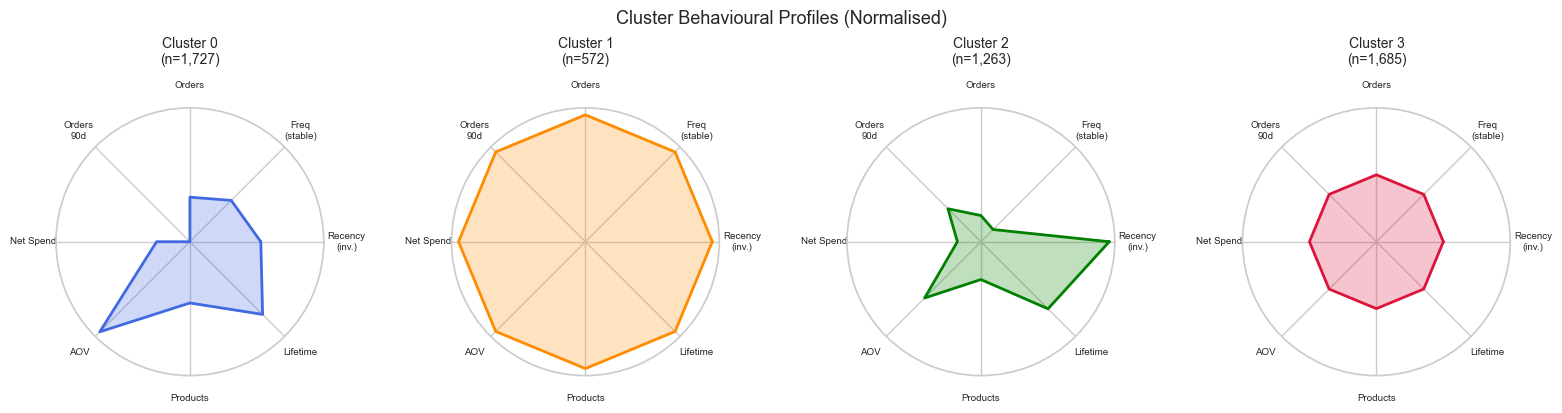

In [17]:
# Spider / radar chart per cluster (recency, frequency, spend, products, lifetime)
from matplotlib.patches import FancyArrowPatch
import numpy as np
import matplotlib.pyplot as plt

radar_metrics = {
    'Recency\n(inv.)':      'FEATURE_recency_days',
    'Freq\n(stable)':       'SEG_purchase_frequency_stable',
    'Orders':               'FEATURE_purchase_order_count',
    'Orders\n90d':          'FEATURE_purchase_order_count_90d',
    'Net Spend':            'FEATURE_total_net_spend',
    'AOV':                  'FEATURE_average_order_value',
    'Products':             'FEATURE_unique_products_purchased',
    'Lifetime':             'FEATURE_customer_lifetime_days',
}

# Normalise 0-1 per metric (invert recency)
radar_df = df_latest.groupby('cluster')[[v for v in radar_metrics.values()]].median()
radar_norm = radar_df.copy()
for col in radar_norm.columns:
    col_range = radar_norm[col].max() - radar_norm[col].min()
    if col_range > 0:
        radar_norm[col] = (radar_norm[col] - radar_norm[col].min()) / col_range
# Invert recency so higher = more recent
radar_norm['FEATURE_recency_days'] = 1 - radar_norm['FEATURE_recency_days']

categories = list(radar_metrics.keys())
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, axes = plt.subplots(1, FINAL_K, figsize=(16, 4), subplot_kw={'projection': 'polar'})
colors = ['royalblue', 'darkorange', 'green', 'crimson']

for i, ax in enumerate(axes):
    vals = radar_norm.loc[i].values.tolist() + [radar_norm.loc[i].values[0]]
    ax.plot(angles, vals, color=colors[i], linewidth=2)
    ax.fill(angles, vals, color=colors[i], alpha=0.25)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, size=7)
    ax.set_yticks([])
    ax.set_title(f'Cluster {i}\n(n={sizes[i]:,})', size=10, pad=12)

plt.suptitle('Cluster Behavioural Profiles (Normalised)', fontsize=13)
plt.tight_layout()
plt.show()

## 10. Frequency Stability: Impact on Clustering

In [18]:
# Compare cluster membership with and without stabilised frequency
# Temporarily swap SEG_purchase_frequency_stable with FEATURE_purchase_frequency

X_raw_unstable = X_raw.copy()
X_raw_unstable['SEG_purchase_frequency_stable'] = np.log1p(
    np.clip(df_latest['FEATURE_purchase_frequency'], 0, None)
)
scaler_us = StandardScaler()
X_scaled_us = pd.DataFrame(scaler_us.fit_transform(X_raw_unstable), columns=SEG_FEATURES, index=X_raw.index)

km_us = KMeans(n_clusters=FINAL_K, random_state=RANDOM_STATE, n_init=20)
labels_us = km_us.fit_predict(X_scaled_us)

# Compare cluster centres / sizes
sizes_stable   = df_latest['cluster'].value_counts().sort_index()
sizes_unstable = pd.Series(labels_us).value_counts().sort_index()

print("Cluster sizes — STABLE frequency:")
print(sizes_stable.to_string())
print("\nCluster sizes — CANONICAL (unstabilised) frequency:")
print(sizes_unstable.to_string())

# Correlation of labels (approximate)
from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(df_latest['cluster'], labels_us)
print(f"\nAdjusted Rand Index (stable vs unstable): {ari:.4f}")
print("(1.0 = identical, 0.0 = random — if ARI is high, stabilisation did not materially change structure)")


Cluster sizes — STABLE frequency:
cluster
0    1727
1     572
2    1263
3    1685

Cluster sizes — CANONICAL (unstabilised) frequency:
0    1903
1     649
2      17
3    2678

Adjusted Rand Index (stable vs unstable): 0.4771
(1.0 = identical, 0.0 = random — if ARI is high, stabilisation did not materially change structure)


## 11. Segment × Propensity Matrix (Phase 3 Preview)

=== SEGMENT × PROPENSITY BAND DISTRIBUTION ===
propensity_band  1_LOW 2_MODERATE 3_HIGH 4_VERY_HIGH
cluster                                             
0                76.5%      18.4%   5.2%        0.0%
1                 0.9%       3.7%  18.5%       76.9%
2                20.8%      49.1%  25.0%        5.1%
3                99.9%       0.1%   0.0%        0.0%


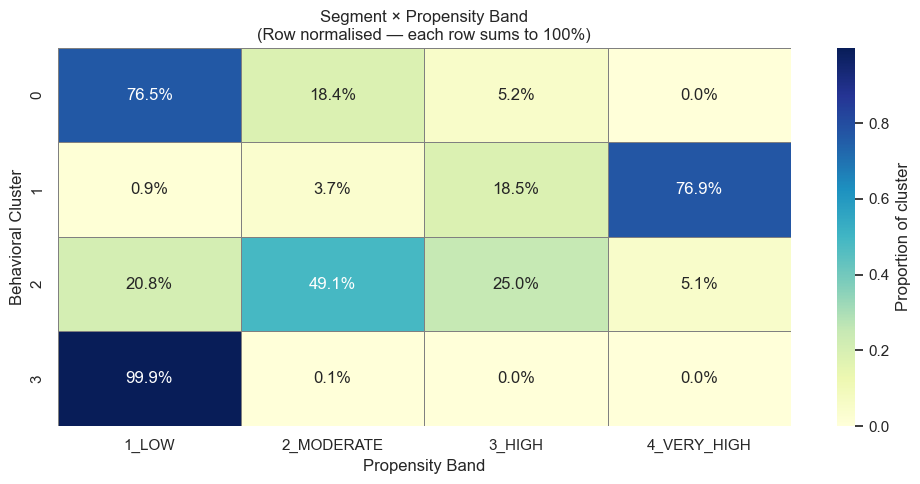

In [19]:
if 'propensity_band' in df_latest.columns and df_latest['propensity_band'].ne('UNKNOWN').any():
    ct = pd.crosstab(df_latest['cluster'], df_latest['propensity_band'], normalize='index')
    print("=== SEGMENT × PROPENSITY BAND DISTRIBUTION ===")
    print(ct.map('{:.1%}'.format).to_string())
    
    plt.figure(figsize=(10, 5))
    sns.heatmap(ct, annot=True, fmt='.1%', cmap='YlGnBu',
                linewidths=0.5, linecolor='gray',
                cbar_kws={'label': 'Proportion of cluster'})
    plt.title("Segment × Propensity Band\n(Row normalised — each row sums to 100%)", fontsize=12)
    plt.ylabel("Behavioral Cluster")
    plt.xlabel("Propensity Band")
    plt.tight_layout()
    plt.show()
    
    ct.to_csv(EXP_DIR / 'segment_propensity_preview.csv')
else:
    print("Propensity model unavailable — Segment × Propensity matrix skipped.")


## 12. Save Artifacts

In [20]:
# Save cluster assignments
cluster_df = df_latest[['customer_id', 'observation_date', 'cluster']].copy()
cluster_df['segment'] = 'Segment_' + cluster_df['cluster'].astype(str)
cluster_df.to_csv(EXP_DIR / 'cluster_profiles.csv', index=False)

# Save model
joblib.dump(final_model, EXP_DIR / 'segmentation_model.pkl')

# Save scaler + feature list for reproducibility
joblib.dump({'scaler': scaler, 'features': SEG_FEATURES}, EXP_DIR / 'segmentation_scaler.pkl')

# Save preliminary (unnamed) labels
cluster_labels = {str(i): f'Segment_{i}' for i in range(FINAL_K)}
with open(EXP_DIR / 'cluster_labels.json', 'w') as f:
    json.dump(cluster_labels, f, indent=4)

print("Artifacts saved:")
print(f"  cluster_profiles.csv      ({len(cluster_df):,} rows)")
print(f"  segmentation_model.pkl")
print(f"  segmentation_scaler.pkl")
print(f"  cluster_labels.json       (placeholder names — update after human review)")


Artifacts saved:
  cluster_profiles.csv      (5,247 rows)
  segmentation_model.pkl
  segmentation_scaler.pkl
  cluster_labels.json       (placeholder names — update after human review)


## 13. Segmentation Validation Report

In [21]:
km_scores = {
    str(k): {
        'silhouette':        round(results_df.loc[(results_df['algorithm']=='KMeans') & (results_df['k']==k), 'silhouette'].values[0], 4),
        'davies_bouldin':    round(results_df.loc[(results_df['algorithm']=='KMeans') & (results_df['k']==k), 'davies_bouldin'].values[0], 4),
        'min_cluster_pct':   round(results_df.loc[(results_df['algorithm']=='KMeans') & (results_df['k']==k), 'min_cluster_pct'].values[0], 4),
    }
    for k in K_RANGE
}

gmm_scores = {
    str(k): {
        'silhouette':      round(results_df.loc[(results_df['algorithm']=='GMM') & (results_df['k']==k), 'silhouette'].values[0], 4),
        'davies_bouldin':  round(results_df.loc[(results_df['algorithm']=='GMM') & (results_df['k']==k), 'davies_bouldin'].values[0], 4),
        'min_cluster_pct': round(results_df.loc[(results_df['algorithm']=='GMM') & (results_df['k']==k), 'min_cluster_pct'].values[0], 4),
    }
    for k in K_RANGE
}

# Cluster profiles for report
cluster_report_profiles = {}
for c in sorted(df_latest['cluster'].unique()):
    sub = df_latest[df_latest['cluster'] == c]
    cluster_report_profiles[str(c)] = {
        'size':                           int(len(sub)),
        'size_pct':                       round(len(sub)/len(df_latest)*100, 2),
        'median_recency_days':            round(sub['FEATURE_recency_days'].median(), 1),
        'median_purchase_order_count':    round(sub['FEATURE_purchase_order_count'].median(), 1),
        'median_purchase_order_count_90d':round(sub['FEATURE_purchase_order_count_90d'].median(), 1),
        'median_total_net_spend':         round(sub['FEATURE_total_net_spend'].median(), 2),
        'median_average_order_value':     round(sub['FEATURE_average_order_value'].median(), 2),
        'median_unique_products':         round(sub['FEATURE_unique_products_purchased'].median(), 1),
        'median_lifetime_days':           round(sub['FEATURE_customer_lifetime_days'].median(), 1),
        'median_stable_freq':             round(sub['SEG_purchase_frequency_stable'].median(), 4),
        'median_cancellation_lines':      round(sub['FEATURE_cancellation_line_count'].median(), 1),
        'median_return_spend_ratio':      round(sub['SEG_return_spend_ratio'].median(), 4),
        'segment_name':                   f'Segment_{c}',
        'segment_name_note':              'PLACEHOLDER — update after human review'
    }

seg_propensity = {}
if 'propensity_band' in df_latest.columns:
    ct_raw = pd.crosstab(df_latest['cluster'], df_latest['propensity_band'], normalize='index')
    for c in ct_raw.index:
        seg_propensity[str(c)] = {band: round(float(ct_raw.loc[c, band]), 4)
                                  for band in ct_raw.columns if band in ct_raw.columns}

report = {
    'status':              'PHASE_2_VALIDATION_COMPLETE_AWAITING_REVIEW',
    'final_algorithm':     'KMeans',
    'final_k':             FINAL_K,
    'k_is_silhouette_optimal': False,
    'selection_justification': (
        'K=4 selected on business criteria. Silhouette is marginally lower than k=2/3 '
        'but K=4 produces four meaningfully distinct behavioral cohorts with no pathological '
        'cluster sizes. K=3 merges the "Established At-Risk" group; K=5 subdivides without '
        'adding interpretable signal. Selection documented in notebook cell 7.'
    ),
    'hdbscan_available':   HAS_HDBSCAN,
    'hdbscan_note':        ('Evaluated and included in comparison.' if HAS_HDBSCAN else
                            'hdbscan package not installed. Algorithm excluded from comparison. '
                            'Comparison limited to KMeans and GMM.'),
    'algorithm_comparison': {
        'KMeans': km_scores,
        'GMM':    gmm_scores,
    },
    'frequency_stability': {
        'issue': ('FEATURE_purchase_frequency uses lifetime_days as denominator. '
                  'Customers with lifetime_days=1 receive frequency=30 (1 order / (1/30)), '
                  'which is semantically misleading for clustering.'),
        'fix':   ('Created SEG_purchase_frequency_stable using max(lifetime_days, 90) '
                  'as denominator. Canonical FEATURE_purchase_frequency NOT modified.'),
        'impact': f'Adjusted Rand Index (stable vs unstable clustering): see notebook cell 10'
    },
    'return_behavior': {
        'finding': ('FEATURE_return_rate and FEATURE_return_line_count are zero for all '
                    'identified customers (expected — see Phase 1 integrity note). '
                    'FEATURE_cancellation_line_count and FEATURE_total_return_amount carry '
                    'valid return signal for active/established clusters. '
                    'SEG_return_spend_ratio (normalised) included as clustering feature.'),
    },
    'cluster_profiles':         cluster_report_profiles,
    'segment_propensity_matrix': seg_propensity,
    'next_step':               'Human review of cluster profiles → assign business names → Phase 3'
}

with open(EXP_DIR / 'segmentation_validation_report.json', 'w') as f:
    json.dump(report, f, indent=4)

print("=== SEGMENTATION VALIDATION REPORT SAVED ===")
print(f"Status: {report['status']}")
print(f"Algorithm: {report['final_algorithm']} k={report['final_k']}")
print(f"Silhouette optimal: {report['k_is_silhouette_optimal']}")
print(f"HDBSCAN evaluated: {report['hdbscan_available']}")
print(f"Next step: {report['next_step']}")


=== SEGMENTATION VALIDATION REPORT SAVED ===
Status: PHASE_2_VALIDATION_COMPLETE_AWAITING_REVIEW
Algorithm: KMeans k=4
Silhouette optimal: False
HDBSCAN evaluated: True
Next step: Human review of cluster profiles → assign business names → Phase 3
